[[-0.03125422 -0.03529893 -0.02715887]
 [-0.01723221 -0.02049152 -0.01386382]
 [ 0.00344329  0.00095019  0.00602514]
 [-0.02204819 -0.02541413 -0.01863581]
 [-0.00976369 -0.01266572 -0.00693445]]


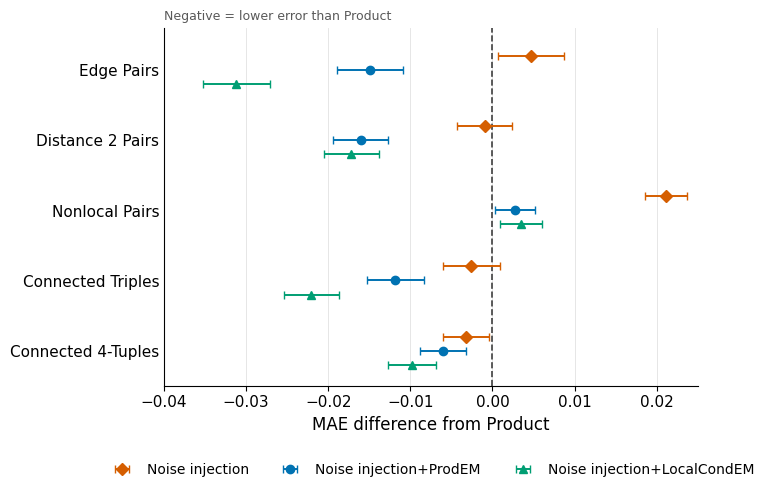

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

results = pd.read_csv(
    "./ibm_results/ibm_correlator_vs_product_sample_bootstrap.csv"
)

group_order = [
    "edge_w2",
    "distance2_w2",
    "nonlocal_w2",
    "connected_w3",
    "connected_w4",
]
group_labels = [
    "Edge Pairs",
    "Distance 2 Pairs",
    "Nonlocal Pairs",
    "Connected Triples",
    "Connected 4-Tuples",
]
columns = [
    "delta_point",
    "ci95_low_centered",
    "ci95_high_centered",
]

def get_intervals(method):
    return (
        results.loc[results["method"] == method]
        .set_index("group")
        .loc[group_order, columns]
        .to_numpy()
    )

y = np.arange(len(group_order))

with plt.rc_context({
    "font.size": 11,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}):
    fig, ax = plt.subplots(
        figsize=(7.5, 4.8),
        layout="constrained",
    )

    def plot_intervals(data, positions, color, marker, label):
        mean, lower, upper = data.T
        ax.errorbar(
            mean,
            positions,
            xerr=np.vstack([mean - lower, upper - mean]),
            fmt=marker,
            linestyle="none",
            color=color,
            markersize=6,
            capsize=3,
            elinewidth=1.4,
            label=label,
            zorder=3,
        )

    offset = 0.20
    plot_intervals(
        get_intervals("Protocol"), y - offset,
        color="#D55E00", marker="D",
        label="Noise injection",
    )
    plot_intervals(
        get_intervals("Protocol+ProdEM"), y,
        color="#0072B2", marker="o",
        label="Noise injection+ProdEM",
    )
    plot_intervals(
        get_intervals("Protocol+CondIQPEM"), y + offset,
        color="#009E73", marker="^",
        label="Noise injection+LocalCondEM",
    )
    print(get_intervals("Protocol+CondIQPEM"))

    ax.set_xlim(-0.04, 0.025)
    ax.xaxis.set_major_locator(MultipleLocator(0.01))
    ax.set_yticks(y, labels=group_labels)
    ax.set_ylim(len(group_order) - 0.5, -0.6)

    ax.axvline(0, color="0.25", linestyle="--", linewidth=1.2)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="0.9", linewidth=0.7)
    ax.tick_params(axis="y", length=0)
    ax.spines[["top", "right"]].set_visible(False)

    ax.set_title(
        "Negative = lower error than Product",
        loc="left", fontsize=9, color="0.35",
    )
    ax.set_xlabel(
        r"MAE difference from Product"
    )
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=3,
        frameon=False,
    )

    # Optional export:
    #fig.savefig("ibm_pauli_word_errors.pdf", bbox_inches="tight")
    # fig.savefig(
    #     "ibm_pauli_word_errors.png", dpi=300, bbox_inches="tight"
    # )

    plt.show()